# Zuber: análisis de viajes en taxi en Chicago

**Autor:** Juan Pablo Quintero

## Descripción del proyecto

Zuber es una nueva empresa de viajes compartidos que se lanza en Chicago. Como analista, mi tarea es encontrar patrones en los datos disponibles para entender las preferencias de los pasajeros y el impacto de factores externos en los viajes.

Para eso voy a:

1. Obtener por web scraping los datos del clima de Chicago en noviembre de 2017.
2. Analizar con SQL los datos de las empresas de taxis de la competencia.
3. Probar la hipótesis de que el clima afecta la duración de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare.


## Descripción de los datos

La base de datos contiene información sobre viajes en taxi en Chicago:

| Tabla             | Contenido            | Campos principales                                                                                                           |
| ----------------- | -------------------- | ---------------------------------------------------------------------------------------------------------------------------- |
| `neighborhoods`   | Barrios de la ciudad | `neighborhood_id`, `name`                                                                                                    |
| `cabs`            | Taxis                | `cab_id`, `vehicle_id`, `company_name`                                                                                       |
| `trips`           | Viajes               | `trip_id`, `cab_id`, `start_ts`, `end_ts`, `duration_seconds`, `distance_miles`, `pickup_location_id`, `dropoff_location_id` |
| `weather_records` | Clima por hora       | `record_id`, `ts`, `temperature`, `description`                                                                              |

**Nota:** `trips` y `weather_records` no tienen una relación directa. Se unen por la hora de inicio del viaje (`trips.start_ts`) y la hora del registro meteorológico (`weather_records.ts`).


## Importar librerías


In [54]:
# Web scraping
import requests
from bs4 import BeautifulSoup

# Manipulación de datos
import pandas as pd

---

## Paso 1. Web scraping del clima

**Objetivo:** extraer de una página web la tabla con el clima por hora de Chicago en noviembre de 2017.

**Para qué sirve:** estos registros son la base para clasificar cada hora como _Good_ o _Bad_ según el clima (Paso 3) y probar la hipótesis sobre la duración de los viajes (Paso 5).


In [55]:
# URL de la página con los registros del clima de Chicago (noviembre de 2017)
URL = 'https://practicum-content.s3.us-west-1.amazonaws.com/data-analyst-eng/moved_chicago_weather_2017.html'

# Petición GET: descarga la página. La respuesta queda en `req`
req = requests.get(URL)

# Parseo: convierte el HTML (req.text) en un objeto navegable usando el parser lxml
soup = BeautifulSoup(req.text, 'lxml')

In [56]:
# Ubicar la tabla por su id (find devuelve un solo elemento, no una lista)
table = soup.find('table', attrs={'id': 'weather_records'})

# Encabezados: texto de cada etiqueta <th>
heading_table = [row.text for row in table.find_all('th')]

# Filas de datos: recorre cada <tr> y salta la fila de encabezados (la que tiene <th>).
# De las demás toma el texto de cada celda <td>
content = []
for row in table.find_all('tr'):
    if not row.find_all('th'):
        content.append([element.text for element in row.find_all('td')])

In [57]:
# Construir el DataFrame con las filas extraídas y los encabezados como nombres de columna
weather_records = pd.DataFrame(content, columns=heading_table)

# Imprimir el DataFrame completo
print(weather_records)

           Date and time Temperature       Description
0    2017-11-01 00:00:00     276.150     broken clouds
1    2017-11-01 01:00:00     275.700  scattered clouds
2    2017-11-01 02:00:00     275.610   overcast clouds
3    2017-11-01 03:00:00     275.350     broken clouds
4    2017-11-01 04:00:00     275.240     broken clouds
..                   ...         ...               ...
692  2017-11-29 20:00:00     281.340        few clouds
693  2017-11-29 21:00:00     281.690      sky is clear
694  2017-11-29 22:00:00     281.070        few clouds
695  2017-11-29 23:00:00     280.060      sky is clear
696  2017-11-30 00:00:00     278.460      sky is clear

[697 rows x 3 columns]


### Revisión del DataFrame obtenido


In [58]:
# Dimensiones: (filas, columnas)
print(weather_records.shape)

(697, 3)


In [59]:
# Tipos de datos y valores no nulos por columna
weather_records.info()

<class 'pandas.DataFrame'>
RangeIndex: 697 entries, 0 to 696
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Date and time  697 non-null    str  
 1   Temperature    697 non-null    str  
 2   Description    697 non-null    str  
dtypes: str(3)
memory usage: 42.0 KB


In [60]:
# Primeras y últimas filas, para confirmar que el rango de fechas es completo
display(weather_records.head())
display(weather_records.tail())

,Date and time,Temperature,Description
0,2017-11-01 00:00:00,276.150,broken clouds
1,2017-11-01 01:00:00,275.700,scattered clouds
2,2017-11-01 02:00:00,275.610,overcast clouds
3,2017-11-01 03:00:00,275.350,broken clouds
4,2017-11-01 04:00:00,275.240,broken clouds


,Date and time,Temperature,Description
692,2017-11-29 20:00:00,281.340,few clouds
693,2017-11-29 21:00:00,281.690,sky is clear
694,2017-11-29 22:00:00,281.070,few clouds
695,2017-11-29 23:00:00,280.060,sky is clear
696,2017-11-30 00:00:00,278.460,sky is clear


In [61]:
# Se guarda una copia en local de la tabla de la página del proyecto
weather_records.to_csv('../data/chicago_weather_nov_2017.csv', index=False)

### Observaciones del Paso 1

- **Volumen y período:** se obtuvieron **697 registros horarios**, desde el 1 de noviembre de 2017 a las 00:00 hasta el 30 de noviembre a las 00:00.

- **Calidad:** no hay valores nulos en ninguna de las 3 columnas ni filas vacías.

- **Tipos de datos:** el scraping devuelve todo como texto, y las 3 columnas quedaron como `str`. Para usarlas en un análisis habría que convertirlas:
  - `Date and time` → `datetime`
  - `Temperature` → numérico (`float`)
  - `Description` es categórica, por lo que puede quedarse como texto.

- **Unidad de temperatura:** por sible lógica los valores de temperatura no corresponden a °C ni a °F. Se consideran que están en **Kelvin**.

- **Relevancia para la hipótesis:** la columna `Description` es la que permite clasificar cada hora como _Bad_ (si contiene "rain" o "storm") o _Good_ para el Paso 3.


---

## Paso 2. Análisis exploratorio de datos (SQL)

Las consultas de este paso se ejecutaron en la base de datos PostgreSQL de la plataforma de TripleTen. Cada consulta también está guardada como archivo en la carpeta `sql/`.

**Técnicas usadas:** `INNER JOIN` entre `trips` y `cabs` por `cab_id`, filtros de fecha con `CAST(... AS DATE)`, agregación con `COUNT` y `GROUP BY`, filtrado de texto con `LIKE` y agrupación condicional con `CASE`.


### Ejercicio 1. Viajes por empresa el 15 y 16 de noviembre de 2017

**Pregunta:** ¿cuántos viajes hizo cada empresa de taxis entre el 15 y el 16 de noviembre de 2017?

```sql
-- Paso 2 · Ejercicio 1
-- Cantidad de viajes en taxi por empresa entre el 15 y el 16 de noviembre de 2017, ordenada de mayor a menor.

SELECT
    c.company_name,
    COUNT(t.trip_id) AS trips_amount
FROM
    trips t
    INNER JOIN cabs c ON t.cab_id = c.cab_id
WHERE
    CAST(t.start_ts AS DATE) BETWEEN '2017-11-15' AND '2017-11-16'
GROUP BY
    c.company_name
ORDER BY
    trips_amount DESC;
```

**Nota:** `start_ts` es un _timestamp_. Comparar directamente con `BETWEEN '2017-11-15' AND '2017-11-16'` dejaría fuera casi todo el día 16 (se interpretaría como `2017-11-16 00:00:00`). Por eso se convierte primero a fecha con `CAST(... AS DATE)`.

**Resultado (primeras 5 de 64 empresas):**

| company_name                    | trips_amount |
| ------------------------------- | -----------: |
| Flash Cab                       |       19,558 |
| Taxi Affiliation Services       |       11,422 |
| Medallion Leasin                |       10,367 |
| Yellow Cab                      |        9,888 |
| Taxi Affiliation Service Yellow |        9,299 |

**Observaciones:**

- **Mercado concentrado:** Flash Cab tiene casi el doble de viajes que la segunda empresa.

- **Calidad de los nombres:** Se observa que en el resultado obtenido hay nombres que podrían ser variantes de nombres de las empresas. Aún no se unifican porque no hay forma de confirmar que sean la misma empresa.


### Ejercicio 2. Empresas "Yellow" y "Blue" del 1 al 7 de noviembre de 2017

**Pregunta:** ¿cuántos viajes hizo cada empresa cuyo nombre contiene "Yellow" o "Blue" entre el 1 y el 7 de noviembre de 2017?

```sql
-- Paso 2 · Ejercicio 2
-- Cantidad de viajes por empresa cuyo nombre contiene "Yellow" o "Blue", entre el 1 y el 7 de noviembre de 2017.

SELECT
    c.company_name AS company_name,
    COUNT(t.trip_id) AS trips_amount
FROM
    trips t
    INNER JOIN cabs c ON t.cab_id = c.cab_id
WHERE
    CAST(t.start_ts AS DATE) BETWEEN '2017-11-01' AND '2017-11-07'
    -- Los paréntesis son necesarios: AND se evalúa antes que OR
    AND (c.company_name LIKE '%Yellow%' OR c.company_name LIKE '%Blue%')
GROUP BY
    c.company_name
ORDER BY
    trips_amount DESC;
```

**Resultado:**

| company_name                      | trips_amount |
| --------------------------------- | -----------: |
| Yellow Cab                        |       33,668 |
| Taxi Affiliation Service Yellow   |       29,213 |
| Blue Ribbon Taxi Association Inc. |       17,675 |
| Blue Diamond                      |        6,764 |

**Observaciones:**

- Las dos empresas "Yellow" están casi que parejas y ambas superan en gran cantidad de viajes a las "Blue".

- Los líderes del mercado como se observa en el anterior ejercicio, "Flash Cab" no tiene "nombre de color", por lo tanto, este filtro no captura a los competidores más fuertes.


### Ejercicio 3. Flash Cab, Taxi Affiliation Services y "Other" del 1 al 7 de noviembre de 2017

**Pregunta:** del 1 al 7 de noviembre de 2017, las empresas más populares fueron Flash Cab y Taxi Affiliation Services. ¿Cuántos viajes hizo cada una, frente a todas las demás empresas agrupadas como "Other"?

```sql
-- Paso 2 · Ejercicio 3
-- Viajes del 1 al 7 de noviembre de 2017 de las dos empresas más populares
-- (Flash Cab y Taxi Affiliation Services); el resto se agrupa como "Other".

SELECT
    CASE
        WHEN c.company_name IN ('Flash Cab', 'Taxi Affiliation Services') THEN c.company_name
        ELSE 'Other'
    END AS company,
    COUNT(t.trip_id) AS trips_amount
FROM
    trips t
    INNER JOIN cabs c ON c.cab_id = t.cab_id
WHERE
    CAST(t.start_ts AS DATE) BETWEEN '2017-11-01' AND '2017-11-07'
GROUP BY
    company
ORDER BY
    trips_amount DESC;
```

**Nota:** los nombres se comparan de forma exacta con `IN`, no con `LIKE`, además, se agrupa por la nueva columna `company`.

**Resultado:**

| company                   | trips_amount | % del total |
| ------------------------- | -----------: | ----------: |
| Other (62 empresas)       |      335,771 |      76.8 % |
| Flash Cab                 |       64,084 |      14.6 % |
| Taxi Affiliation Services |       37,583 |       8.6 % |
| **Total**                 |  **437,438** |   **100 %** |

**Observaciones:**

- Entre las dos empresas líderes suman casi una cuarta parte de todos los viajes de la semana (23.2 %). Las otras empresas se reparten el resto.

- Flash Cab hace casi el doble de los viajes de Taxi Affiliation Services. Para Zuber es el principal competidor como referencia.


---

## Paso 3. Consultas para probar la hipótesis (SQL)

**Hipótesis a preparar:** la duración de los viajes desde el Loop hasta el Aeropuerto Internacional O'Hare cambia los sábados lluviosos.

En este paso se construye, con tres consultas encadenadas, el dataset que se usa en la prueba de hipótesis (Paso 5): primero se identifican los barrios, luego se clasifica el clima de cada hora y al final se unen ambos con los viajes.

**Técnicas usadas:** escape de comillas en texto, `CASE` con `LIKE`, subconsulta dentro de un `JOIN`, unión de tablas sin llave directa (por hora) y extracción del día de la semana con `EXTRACT(ISODOW ...)`.


### Ejercicio 4. Identificadores de los barrios Loop y O'Hare

**Pregunta:** ¿cuáles son los `neighborhood_id` del Loop y de O'Hare?

```sql
-- Paso 3 · Ejercicio 4
-- Identificadores de los barrios Loop y O'Hare en la tabla neighborhoods.
-- La comilla simple de O'Hare se escapa duplicándola ('O''Hare').

SELECT
    neighborhood_id,
    name
FROM
    neighborhoods
WHERE
    name = 'O''Hare'
    OR name = 'Loop';
```

**Nota:** en SQL los textos van entre comillas simples. Como _O'Hare_ tiene una comilla simple dentro, se escapa duplicándola (`'O''Hare'`).

**Resultado:**

| neighborhood_id | name   |
| --------------: | ------ |
|              50 | Loop   |
|              63 | O'Hare |


### Ejercicio 5. Clasificación del clima por hora (Good / Bad)

**Pregunta:** para cada hora de `weather_records`, ¿el clima fue _Bad_ (la descripción contiene "rain" o "storm") o _Good_?

```sql
-- Paso 3 · Ejercicio 5
-- Clasificación de cada hora de weather_records según el clima:
-- "Bad" si la descripción contiene "rain" o "storm"; "Good" en cualquier otro caso.

SELECT
    ts,
    CASE
        WHEN description LIKE '%rain%' OR description LIKE '%storm%' THEN 'Bad'
        ELSE 'Good'
    END AS weather_conditions
FROM
    weather_records;
```

**Resultado (fragmento):** una fila por hora.

| ts                  | weather_conditions |
| ------------------- | ------------------ |
| 2017-11-02 02:00:00 | Good               |
| 2017-11-02 03:00:00 | Bad                |
| 2017-11-02 04:00:00 | Bad                |
| …                   | …                  |

**Observaciones:**

- Predominan ampliamente las horas _Good_.


### Ejercicio 6. Viajes del Loop a O'Hare los sábados, con su clima

**Pregunta:** ¿qué viajes empezaron un sábado en el Loop (50) y terminaron en O'Hare (63), con qué condición climática y cuánto duraron? Se ignoran los viajes sin datos de clima.

```sql
-- Paso 3 · Ejercicio 6
-- Viajes del Loop (50) a O'Hare (63) que empezaron un sábado, con la condición
-- climática de la hora de inicio y su duración (resultado exportado como project_sql_result_07.csv).
-- La subconsulta reutiliza la clasificación Good/Bad del ejercicio 5. El INNER JOIN
-- descarta los viajes sin registro de clima a esa hora.

SELECT
    t.start_ts,
    ws.weather_conditions,
    t.duration_seconds
FROM
    trips t
    INNER JOIN (
        SELECT
            ts,
            CASE
                WHEN description LIKE '%rain%' OR description LIKE '%storm%' THEN 'Bad'
                ELSE 'Good'
            END AS weather_conditions
        FROM
            weather_records
    ) AS ws ON ws.ts = t.start_ts
WHERE
    t.pickup_location_id = 50
    AND t.dropoff_location_id = 63
    -- ISODOW: lunes = 1 ... domingo = 7, por lo que el sábado es 6
    AND EXTRACT(ISODOW FROM t.start_ts) = 6
ORDER BY
    t.trip_id;
```

**Notas:**

- **Subconsulta:** la consulta del ejercicio 5 se usa como una tabla virtual (`ws`) con las columnas `ts` y `weather_conditions`. En PostgreSQL, una subconsulta dentro de un `JOIN` necesita alias obligatoriamente.

- **Unión sin llave directa:** `trips` y `weather_records` se unen por la hora (`t.start_ts = ws.ts`). Las dos están redondeadas a la hora, así que coinciden y no es necesario castear.

- **`INNER JOIN`:** cumple la condición de ignorar los viajes sin registro de clima.

- **Orden:** se ordena por `trip_id` aunque esa columna no aparezca en el `SELECT`.

- Solo aparecen los cuatro sábados de noviembre de 2017: **4, 11, 18 y 25**.

**Resultado (primeras filas):**

| start_ts            | weather_conditions | duration_seconds |
| ------------------- | ------------------ | ---------------: |
| 2017-11-25 12:00:00 | Good               |            1,380 |
| 2017-11-25 16:00:00 | Good               |            2,410 |
| 2017-11-25 14:00:00 | Good               |            1,920 |
| 2017-11-25 12:00:00 | Good               |            1,543 |
| 2017-11-04 10:00:00 | Good               |            2,512 |


---

## Paso 4. Análisis exploratorio de datos (Python)

**Objetivo:** estudiar los resultados de las consultas SQL del Paso 2 para identificar a las empresas de taxis con más viajes y los barrios donde terminan más viajes.

**Datasets:**
| Archivo | Contenido |
|---|---|
| `project_sql_result_01.csv` | `company_name`: empresa de taxis · `trips_amount`: número de viajes del 15 y 16 de noviembre de 2017 |
| `project_sql_result_04.csv` | `dropoff_location_name`: barrio donde terminó el viaje · `average_trips`: promedio de viajes que terminaron en ese barrio en noviembre de 2017 |


### 4.1 Librerías


In [62]:
# Manejo de rutas
from pathlib import Path

# Visualización de datos
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter  # separador de miles en los ejes

### 4.2 Carga de los datos


In [63]:
# Cargar project_sql_result_01.csv en un DataFrame con un nombre descriptivo (companies)
# Cargar project_sql_result_04.csv en un DataFrame con un nombre descriptivo (neighborhoods)

base_dir = Path.cwd().parent
data_dir = base_dir / 'data'

companies_file_path = data_dir / 'project_sql_result_01.csv'
neighborhoods_file_path = data_dir / 'project_sql_result_04.csv'

companies = pd.read_csv(companies_file_path)
neighborhoods = pd.read_csv(neighborhoods_file_path)

### 4.3 Estudio de los datos

#### Empresas de taxis (`project_sql_result_01.csv`)


In [64]:
# dimensiones y primeras filas
print(
    f'El df de companies posee {companies.shape[0]} filas x {companies.shape[1]} columnas')
print('=' * 50)

# Formatea todos los números enteros/flotantes con separador de miles en la vista
display(companies.head().style.format(thousands=','))

El df de companies posee 64 filas x 2 columnas


,company_name,trips_amount
0,Flash Cab,"19,558"
1,Taxi Affiliation Services,"11,422"
2,Medallion Leasin,"10,367"
3,Yellow Cab,"9,888"
4,Taxi Affiliation Service Yellow,"9,299"


In [65]:
# tipos de datos y valores no nulos
companies.info()

<class 'pandas.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   company_name  64 non-null     str  
 1   trips_amount  64 non-null     int64
dtypes: int64(1), str(1)
memory usage: 2.5 KB


In [66]:
# resumen estadístico de trips_amount
display(companies.describe().style.format(thousands=',', precision=2))

,trips_amount
count,64.00
mean,"2,145.48"
std,"3,812.31"
min,2.00
25%,20.75
50%,178.50
75%,"2,106.50"
max,"19,558.00"


In [67]:
# valores nulos y filas duplicadas
print('Registros nulos')
print('=' * 18)
print(companies.isnull().sum())
print()
print('Registro duplicados')
print('=' * 18)
print(companies.duplicated().sum())

Registros nulos
company_name    0
trips_amount    0
dtype: int64

Registro duplicados
0


#### Barrios de destino (`project_sql_result_04.csv`)


In [68]:
# dimensiones y primeras filas
print(
    f'El df de neighborhoods posee {neighborhoods.shape[0]} filas x {neighborhoods.shape[1]} columnas')
print('=' * 50)

# Formatea todos los números enteros/flotantes con separador de miles en la vista
display(neighborhoods.head().style.format(thousands=',', precision=2))

El df de neighborhoods posee 94 filas x 2 columnas


,dropoff_location_name,average_trips
0,Loop,"10,727.47"
1,River North,"9,523.67"
2,Streeterville,"6,664.67"
3,West Loop,"5,163.67"
4,O'Hare,"2,546.90"


In [69]:
# tipos de datos y valores no nulos
neighborhoods.info()

<class 'pandas.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     str    
 1   average_trips          94 non-null     float64
dtypes: float64(1), str(1)
memory usage: 2.6 KB


In [70]:
# resumen estadístico de average_trips
display(neighborhoods.describe().style.format(thousands=',', precision=2))

,average_trips
count,94.00
mean,599.95
std,"1,714.59"
min,1.80
25%,14.27
50%,52.02
75%,298.86
max,"10,727.47"


In [71]:
# valores nulos y filas duplicadas
print('Registros nulos')
print('=' * 18)
print(neighborhoods.isnull().sum())
print()
print('Registro duplicados')
print('=' * 18)
print(neighborhoods.duplicated().sum())

Registros nulos
dropoff_location_name    0
average_trips            0
dtype: int64

Registro duplicados
0


#### Observaciones de los datos

**`companies`**

- **64 filas × 2 columnas**, sin valores nulos ni filas duplicadas.

- `trips_amount` va de **2** a **19,558** viajes.

- La **media (2,145.48) es mucho mayor que la mediana (178.50)**: distribución simétrica muy sesgada positivamente. Pocas empresas concentran una gran cantidad de viajes, y la mitad de las empresas hizo menos de 179 viajes.

**`neighborhoods`**

- **94 filas × 2 columnas**, sin valores nulos ni filas duplicadas.

- `average_trips` va de **1.80** a **10,727.47** viajes promedio.

- Ocurre lo mismo: la **media (599.95) supera ampliamente a la mediana (52.02)**. Unos pocos barrios reciben la mayoría de los viajes, mientras que el 75 % de los barrios recibe menos de 300 viajes promedio.


### 4.4 Verificación de los tipos de datos

Se revisa, columna por columna, si el tipo asignado por pandas corresponde a lo que representa cada dato:

| Columna                 | Tipo original | ¿Correcto?   | Justificación                                                                                 |
| ----------------------- | ------------- | ------------ | --------------------------------------------------------------------------------------------- |
| `company_name`          | `str`         | ✅           | Nombre de la empresa: texto                                                                   |
| `trips_amount`          | `int64`       | ✅           | Conteo de viajes: siempre es un número entero                                                 |
| `dropoff_location_name` | `str`         | ✅           | Nombre del barrio: texto                                                                      |
| `average_trips`         | `float64`     | ⚠️ Se ajusta | Es un promedio y por eso trae decimales, pero representa **viajes**, que son unidades enteras |


In [72]:
# (solo si alguna columna requiere conversión): convertir el tipo y verificar con info()
neighborhoods['average_trips'] = neighborhoods['average_trips'].round().astype(
    int)

# Verificar el resultado de la conversión
print(neighborhoods.dtypes)

dropoff_location_name      str
average_trips            int64
dtype: object


**Conclusión sobre los tipos:**

- `company_name`, `trips_amount` y `dropoff_location_name` ya tenían el tipo correcto y **no requieren conversión**.

- `average_trips` se **redondeó y se convirtió a entero (`int`)**, porque el análisis compara volúmenes de viajes entre barrios y los decimales no aportan a esa comparación.


### 4.5 Top 10 de barrios por número de finalizaciones


In [73]:
# ordenar los barrios de mayor a menor por average_trips, quedarse con los 10 primeros
# y guardarlos en una variable (se usa en el gráfico 2)

top_neighborhoods = neighborhoods.sort_values(
    by='average_trips', ascending=False).head(10)

In [74]:
# mostrar el top 10
display(top_neighborhoods.style.format(thousands=","))

,dropoff_location_name,average_trips
0,Loop,"10,727"
1,River North,"9,524"
2,Streeterville,"6,665"
3,West Loop,"5,164"
4,O'Hare,"2,547"
5,Lake View,"2,421"
6,Grant Park,"2,069"
7,Museum Campus,"1,510"
8,Gold Coast,"1,364"
9,Sheffield & DePaul,"1,260"


### 4.6 Gráficos

Los dos gráficos siguen las mismas reglas de diseño: **barras horizontales** (los nombres se leen sin girarlos), **orden de mayor a menor**, **un solo color base** con la barra clave **resaltada**, **etiquetas de valor** con separador de miles y un **título que resume el hallazgo**.


In [ ]:
# Configuración visual común para los dos gráficos del Paso 4
# Se define una sola vez para que ambos gráficos sean consistentes

sns.set_theme(style='whitegrid')

COLOR_BASE = '#B0BEC5'       # gris azulado: barras sin resaltar
COLOR_HIGHLIGHT = '#1565C0'  # azul intenso: barras que se quieren destacar
# gris muy claro: barra que agrupa varias categorías ("Otras")
COLOR_GROUP = '#E3E8EB'
COLOR_SUBTITLE = '#546E7A'   # gris para subtítulos

#### Gráfico 1. Empresas de taxis y número de viajes (15 y 16 de noviembre de 2017)


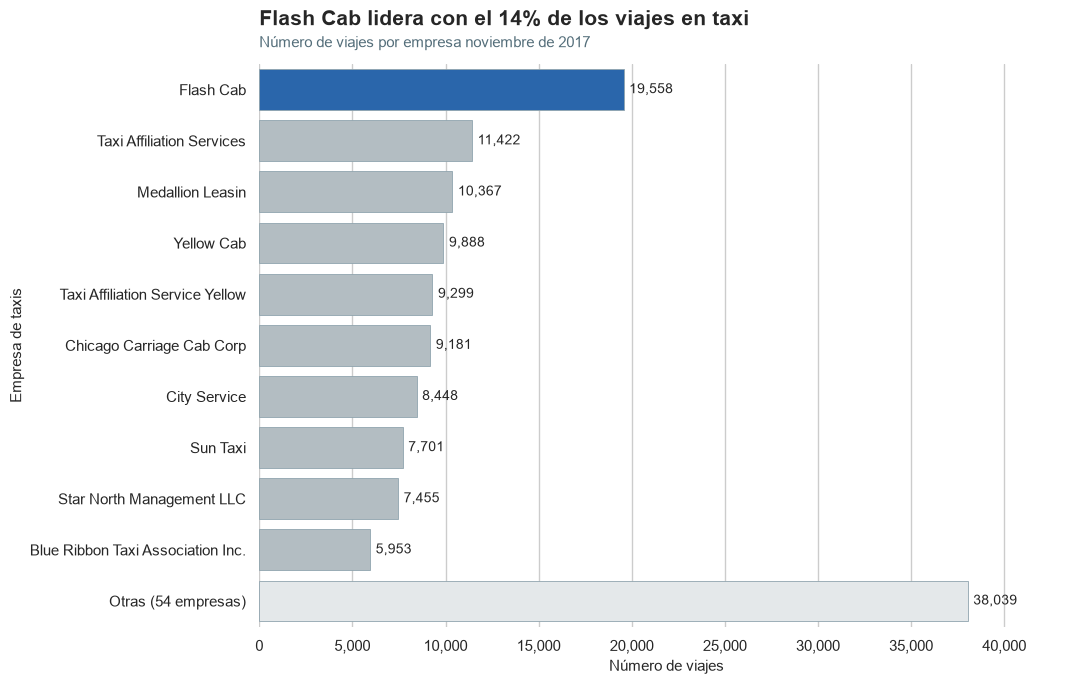

In [ ]:
# 1. PREPARAR LOS DATOS
# Se grafican las 10 empresas principales y el resto se agrupa en una barra "Otras"
TOP_N = 10

companies_sorted = companies.sort_values(by='trips_amount', ascending=False)
top_companies = companies_sorted.head(TOP_N)

# Suma de los viajes de las empresas que quedan fuera del top
others = pd.DataFrame({
    'company_name': [f'Otras ({len(companies_sorted) - TOP_N} empresas)'],
    'trips_amount': [companies_sorted['trips_amount'].iloc[TOP_N:].sum()]
})

companies_plot = pd.concat([top_companies, others], ignore_index=True)

# Colores: el líder resaltado, el grupo "Otras" en gris claro y el resto en el color base
leader = top_companies.iloc[0]['company_name']
colors = [
    COLOR_HIGHLIGHT if name == leader
    else COLOR_GROUP if name.startswith('Otras')
    else COLOR_BASE
    for name in companies_plot['company_name']
]

# Participación del líder sobre el total de viajes (para el título)
leader_share = top_companies.iloc[0]['trips_amount'] / \
    companies['trips_amount'].sum()

# 2. CREAR LA FIGURA
fig, ax = plt.subplots(figsize=(11, 7))

# 3. DIBUJAR (hue + legend=False evita el FutureWarning de seaborn 0.13 al usar palette)
sns.barplot(
    data=companies_plot,
    x='trips_amount',
    y='company_name',
    hue='company_name',
    palette=colors,
    legend=False,
    edgecolor='#90A4AE',
    linewidth=0.6,
    ax=ax
)

# 4. ETIQUETAS DE VALOR (con hue, seaborn crea un contenedor por barra)
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:,.0f}' for v in container.datavalues],
                 padding=4, fontsize=10)

# 5. TEXTOS
ax.set_title(f'{leader} lidera con el {leader_share:.0%} de los viajes en taxi',
             loc='left', fontsize=15, fontweight='bold', pad=28)
ax.text(0, 1.03, 'Número de viajes por empresa noviembre de 2017',
        transform=ax.transAxes, fontsize=10.5, color=COLOR_SUBTITLE)
ax.set_xlabel('Número de viajes', fontsize=11)
ax.set_ylabel('Empresa de taxis', fontsize=11)

# 6. LIMPIEZA VISUAL
# margen para la etiqueta más larga
ax.set_xlim(0, companies_plot['trips_amount'].max() * 1.15)
ax.xaxis.set_major_formatter(StrMethodFormatter(
    '{x:,.0f}'))  # separador de miles en el eje X
# solo cuadrícula vertical
ax.grid(axis='y', visible=False)
sns.despine(left=True, bottom=True)

# 7. MOSTRAR
plt.tight_layout()
plt.show()

**Conclusión del gráfico 1:**

- **Flash Cab es el líder claro**, con 19,558 viajes (14 % del total). Hace casi el doble de viajes de la segunda empresa, Taxi Affiliation Services (11,422).

- **Hay un segundo nivel muy competido:** de la 2da a la 9na posición, las empresas están en un rango parecido (entre ~7,500 y ~11,400 viajes).

- **La cola larga pesa:** las 54 empresas fuera del top suman 38,039 viajes, el 28%. Las 10 principales concentran el 72%.

- **Para Zuber:** el mercado está bastante concentrado pero se podría decir que no hay un monopolio como tal.


#### Gráfico 2. Top 10 de barrios por número de finalizaciones (noviembre de 2017)

Se resaltan **Loop** (origen) y **O'Hare** (destino), los dos barrios de la hipótesis que se prueba en el Paso 5.


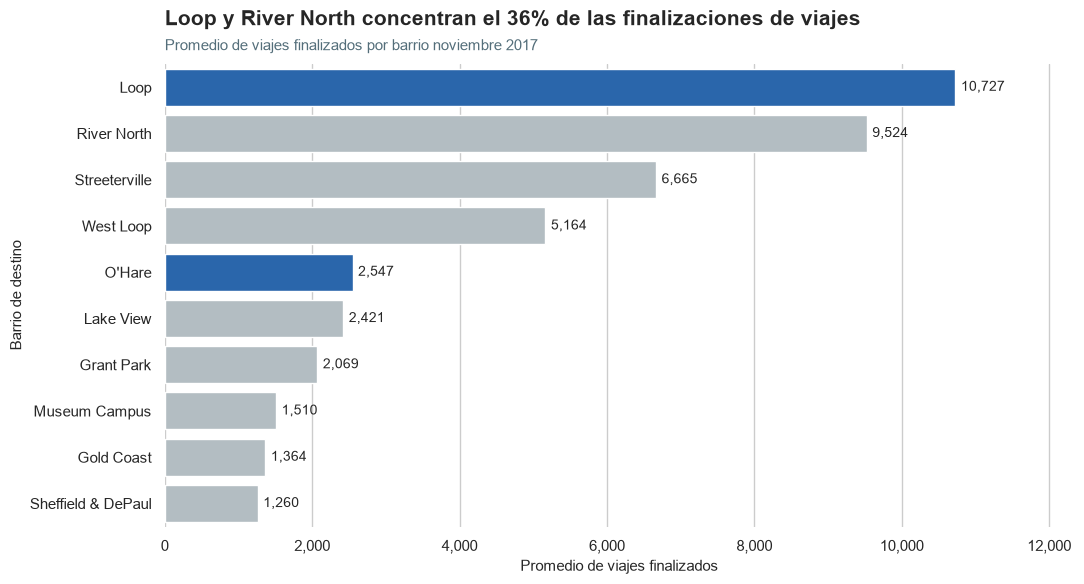

In [ ]:
# 1. PREPARAR LOS DATOS
# top_neighborhoods ya está ordenado de mayor a menor (bloque 4.5)
# Se resaltan Loop (origen) y O'Hare (destino): son los barrios de la hipótesis del Paso 5
HIGHLIGHT_NEIGHBORHOODS = ['Loop', "O'Hare"]

colors = [
    COLOR_HIGHLIGHT if name in HIGHLIGHT_NEIGHBORHOODS else COLOR_BASE
    for name in top_neighborhoods['dropoff_location_name']
]

# Participación de los dos primeros barrios sobre el total de finalizaciones (para el título)
top2_share = top_neighborhoods['average_trips'].head(
    2).sum() / neighborhoods['average_trips'].sum()
top2_names = ' y '.join(top_neighborhoods['dropoff_location_name'].head(2))

# 2. CREAR LA FIGURA
fig, ax = plt.subplots(figsize=(11, 6))

# 3. DIBUJAR
sns.barplot(
    data=top_neighborhoods,
    x='average_trips',
    y='dropoff_location_name',
    hue='dropoff_location_name',
    palette=colors,
    legend=False,
    ax=ax
)

# 4. ETIQUETAS DE VALOR
for container in ax.containers:
    ax.bar_label(container, labels=[f'{v:,.0f}' for v in container.datavalues],
                 padding=4, fontsize=10)

# 5. TEXTOS
ax.set_title(f'{top2_names} concentran el {top2_share:.0%} de las finalizaciones de viajes',
             loc='left', fontsize=15, fontweight='bold', pad=28)
ax.text(0, 1.03, "Promedio de viajes finalizados por barrio noviembre 2017",
        transform=ax.transAxes, fontsize=10.5, color=COLOR_SUBTITLE)
ax.set_xlabel('Promedio de viajes finalizados', fontsize=11)
ax.set_ylabel('Barrio de destino', fontsize=11)

# 6. LIMPIEZA VISUAL
ax.set_xlim(0, top_neighborhoods['average_trips'].max() * 1.15)
ax.xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
ax.grid(axis='y', visible=False)
sns.despine(left=True, bottom=True)

# 7. MOSTRAR
plt.tight_layout()
plt.show()

**Conclusión del gráfico 2:**

- **Loop (10,727) y River North (9,524) son los principales destinos**, y juntos concentran el 36% de todas las finalizaciones. Con Streeterville y West Loop, los 4 primeros barrios suman el 57%.

- **O'Hare aparece en el 5to lugar** (2,547 viajes promedio), a pesar de estar lejos del centro.

- **El top 10 concentra el 77% de las finalizaciones**, los otros 84 barrios se reparten el 23%.

- **Para Zuber:** conviene concentrar la oferta de conductores en el top 4 de barrios y se incluye a **O'Hare**, porque, la ruta **Loop -> O'Hare** une el destino más popular con el aeropuerto, y por eso es la que se analiza en la prueba de hipótesis.


### 4.7 Conclusiones del Paso 4

1. **Competencia:** el mercado de taxis de Chicago tiene un líder claro (**Flash Cab**, 14% de los viajes), un grupo de 8 a 9 empresas medianas con volúmenes parecidos y con 54 competidores pequeños. Para Zuber, Flash Cab es la referencia, pero el mercado no está monopolizado.

2. **Demanda geográfica:** los viajes terminan sobre todo en **4 barrios principales** (Loop, River North, Streeterville y West Loop concentran el 57%). **O'Hare** es el destino fuera de estos principales.

3. **Distribuciones muy sesgadas:** tanto en empresas como en barrios, la media supera ampliamente a la mediana. Pocos compañías y pocas zonas concentran la mayor parte de la operación.


---

## Paso 5. Prueba de hipótesis

> _Pendiente_


---

## Conclusión general

> _Pendiente_
